# Milestone 4 | CFPB Consumer Complaint Narrative Analysis

**Text Mining Research & Analytics Team**

### Research Objective

The purpose of this analysis was to identify patterns within actual consumer-written credit card complaints submitted to the Consumer Financial Protection Bureau (CFPB). Our previous analysis relied on standardized complaint categories, so this milestone focused on examining the language consumers used to describe their experiences.

I used Python to perform sentiment analysis, topic modeling, clustering, and predictive classification. These techniques allowed us to identify recurring complaint themes, evaluate similarities between narratives, and determine how accurately narrative text could predict CFPB issue categories.

### Dataset and Methodology

The original dataset contained 93,626 credit card complaints. After recovering and matching consumer narratives from historical CFPB archives, 28,841 complaints contained usable narrative text.

For this analysis, I selected a reproducible sample of 5,000 records using a random seed of 42. After preprocessing, 4,999 narratives were retained for analysis.

The analysis included TF-IDF vectorization, TextBlob sentiment analysis, Non-negative Matrix Factorization (NMF), MiniBatch K-Means clustering, and supervised classification. Model performance was evaluated using held-out test data.

Sentiment scores were treated as measures of language polarity rather than direct indicators of customer satisfaction. Topic modeling and clustering were used to explore patterns within the narratives rather than establish definitive complaint classifications.

## 1. Data Setup

Imported the required Python libraries and configured the dataset for analysis. The CFPB consumer complaint narratives serve as the primary source for sentiment analysis, topic modeling, clustering, and predictive classification.

In [1]:

from pathlib import Path
import re, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from textblob import TextBlob
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF, TruncatedSVD
from sklearn.cluster import MiniBatchKMeans
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score

SEED = 42
SAMPLE_SIZE = 5000  # Set to None for all records
out = Path('CFPB_Milestone4_Results')
out.mkdir(exist_ok=True)
input_path = Path('CFPB_Milestone4_Narratives_Only.csv')
if not input_path.exists():
    try:
        from google.colab import files
        print('Upload CFPB_Milestone4_Narratives_Only.csv')
        uploaded = files.upload()
        if input_path.name not in uploaded:
            raise FileNotFoundError('Please upload the requested CSV file.')
    except ImportError:
        raise FileNotFoundError(f'Place {input_path.name} in the notebook working directory.')
print('Input file:', input_path.resolve())

Upload CFPB_Milestone4_Narratives_Only.csv


Saving CFPB_Milestone4_Narratives_Only.csv to CFPB_Milestone4_Narratives_Only.csv
Input file: /content/CFPB_Milestone4_Narratives_Only.csv


## 2. Data Preparation
Reviewed the dataset and prepared the narrative text for analysis. Cleaning included removing URLs, redaction placeholders, and unnecessary punctuation. I retained the original narrative alongside the cleaned version so the analysis could be traced back to the source text.

In [2]:
def clean_narrative(s):
    s = re.sub(r'http\S+|www\.\S+', ' ', str(s))
    s = re.sub(r'\bX{2,}\b', ' ', s, flags=re.I)
    s = re.sub(r"[^a-zA-Z\s']", ' ', s)
    return re.sub(r'\s+', ' ', s).strip().lower()

raw = pd.read_csv(input_path, low_memory=False)
required = ['Complaint ID', 'Issue', 'Consumer complaint narrative']
missing = [c for c in required if c not in raw.columns]
if missing:
    raise ValueError(f'Missing required columns: {missing}')
print('Original shape:', raw.shape)
print('Nonmissing narratives:', raw['Consumer complaint narrative'].notna().sum())
df = raw.dropna(subset=['Consumer complaint narrative','Issue'])
if SAMPLE_SIZE is not None:
    df = df.sample(n=min(SAMPLE_SIZE, len(df)), random_state=SEED)
df = df.copy()
df['narrative_clean'] = df['Consumer complaint narrative'].map(clean_narrative)
df = df[df.narrative_clean.str.len() >= 30].copy().reset_index(drop=True)
df['narrative_word_count'] = df.narrative_clean.str.split().str.len()
print('Analyzed records:', len(df), '| Unique cleaned narratives:', df.narrative_clean.nunique())
display(df[['Issue','Consumer complaint narrative','narrative_word_count']].head(3))

Original shape: (28841, 13)
Nonmissing narratives: 28841
Analyzed records: 4999 | Unique cleaned narratives: 4971


,Issue,Consumer complaint narrative,narrative_word_count
0,Fees or interest,Synchrony Bank assessed returned payment fees ...,247
1,Fees or interest,My robinhood credit card was charged {$32.00} ...,54
2,"Other features, terms, or problems",We have been trying to pay down a credit card ...,507


## 3. Sentiment Analysis
I used TextBlob to measure the polarity of each complaint narrative and categorize the language as negative, neutral, or positive. These scores reflect the wording of the complaint, not whether the consumer had a positive experience or received a satisfactory resolution.

,count,percent
sentiment_label,,
Negative,1094,21.9
Neutral,2161,43.2
Positive,1744,34.9


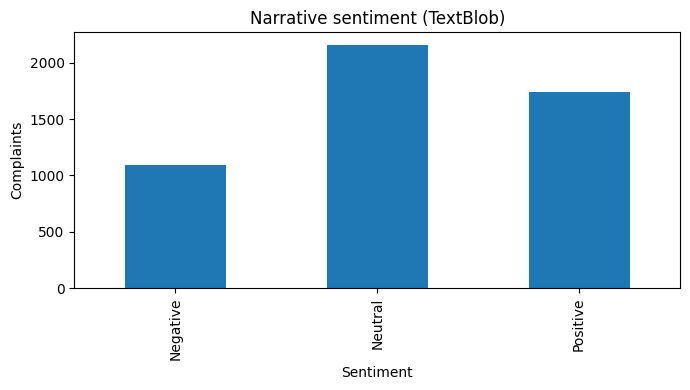

In [3]:
scores = df['Consumer complaint narrative'].map(lambda t: TextBlob(str(t)).sentiment)
df['sentiment_polarity'] = [round(s.polarity, 4) for s in scores]
df['sentiment_subjectivity'] = [round(s.subjectivity, 4) for s in scores]
df['sentiment_label'] = pd.cut(df.sentiment_polarity, [-1.001,-0.05,0.05,1.001], labels=['Negative','Neutral','Positive'])
counts = df.sentiment_label.value_counts().reindex(['Negative','Neutral','Positive'])
display(pd.DataFrame({'count':counts, 'percent':(counts/len(df)*100).round(1)}))
ax = counts.plot.bar(figsize=(7,4), title='Narrative sentiment (TextBlob)')
ax.set(xlabel='Sentiment', ylabel='Complaints')
plt.tight_layout(); plt.savefig(out/'sentiment_distribution.png',dpi=150); plt.show()

## 4. Topic Modeling: TF-IDF + NMF
I used TF-IDF and Non-negative Matrix Factorization (NMF) to identify recurring themes within the complaint narratives. This approach allows patterns to emerge from the language consumers used instead of limiting the analysis to the existing CFPB issue categories.

,topic_id,top_terms,count
0,1,"card, account, called, credit, credit card, to...",1715
1,2,"dispute, merchant, evidence, charge, refund, t...",1105
2,3,"reporting, account, credit reporting, inaccura...",861
3,4,"report, fraudulent, credit report, identity, t...",634
4,5,"late, late payment, entries, payment, payment ...",178
5,6,"american, american express, express, amex, poi...",319
6,7,"wells, fargo, wells fargo, fargo credit, card,...",187


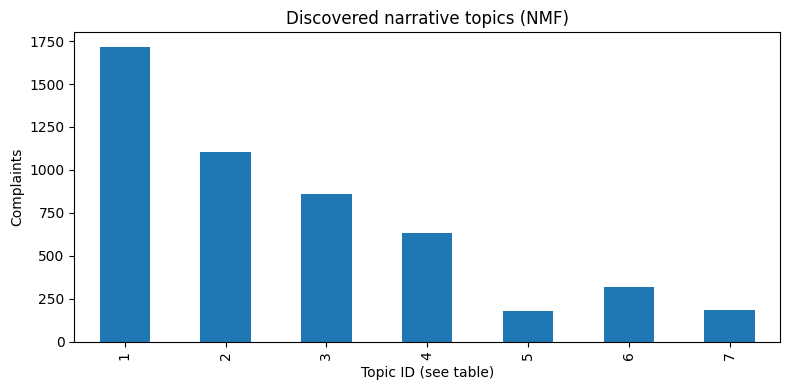

In [4]:
vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1,2), min_df=8, max_df=.85, max_features=5000, sublinear_tf=True)
X = vectorizer.fit_transform(df.narrative_clean)
terms = np.array(vectorizer.get_feature_names_out())
nmf = NMF(n_components=7, random_state=SEED, init='nndsvda', max_iter=100)
topic_weights = nmf.fit_transform(X)
df['topic_id'] = topic_weights.argmax(axis=1) + 1
topic_names = {i+1: ', '.join(terms[np.argsort(nmf.components_[i])[-8:][::-1]]) for i in range(7)}
df['topic_keywords'] = df.topic_id.map(topic_names)
topic_summary = pd.DataFrame({'topic_id':range(1,8),'top_terms':[topic_names[i] for i in range(1,8)], 'count':[int((df.topic_id==i).sum()) for i in range(1,8)]})
display(topic_summary)
ax = df.topic_id.value_counts().sort_index().plot.bar(figsize=(8,4), title='Discovered narrative topics (NMF)')
ax.set(xlabel='Topic ID (see table)', ylabel='Complaints')
plt.tight_layout(); plt.savefig(out/'topic_distribution.png',dpi=150); plt.show()

## 5. Unsupervised Clustering: SVD + MiniBatchKMeans
I applied dimensionality reduction and MiniBatch K-Means to group complaints with similar text patterns. These clusters provide another way to examine relationships between narratives, although the cluster numbers do not represent verified complaint categories.

sentiment_label,Negative,Neutral,Positive
cluster_id,,,
1,284,367,297
2,359,635,544
3,178,396,301
4,102,307,338
5,43,145,69
6,128,311,195


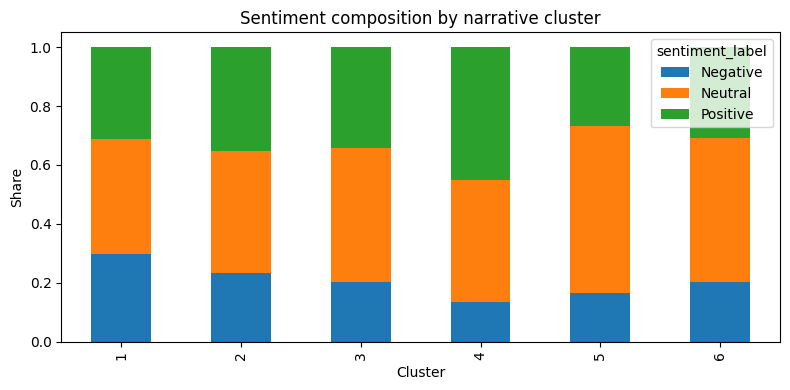

In [5]:
svd = TruncatedSVD(n_components=35, random_state=SEED)
reduced = svd.fit_transform(X)
reduced = reduced/(np.linalg.norm(reduced,axis=1,keepdims=True)+1e-10)
km = MiniBatchKMeans(n_clusters=6,random_state=SEED,batch_size=1024,n_init=3,max_iter=100)
df['cluster_id'] = km.fit_predict(reduced)+1
cluster_sentiment = pd.crosstab(df.cluster_id,df.sentiment_label)
display(cluster_sentiment)
ax = pd.crosstab(df.cluster_id,df.sentiment_label,normalize='index').plot.bar(stacked=True,figsize=(8,4),title='Sentiment composition by narrative cluster')
ax.set(xlabel='Cluster',ylabel='Share')
plt.tight_layout();plt.savefig(out/'cluster_sentiment.png',dpi=150);plt.show()

In [8]:

# Identify the most common terms within each cluster

cluster_rows = []

for cluster_id in sorted(df['cluster_id'].unique()):
    cluster_mask = (df['cluster_id'] == cluster_id).to_numpy()

    cluster_matrix = X[cluster_mask]
    mean_tfidf = np.asarray(cluster_matrix.mean(axis=0)).ravel()

    top_indices = mean_tfidf.argsort()[-10:][::-1]
    top_terms = terms[top_indices]

    cluster_rows.append({
        'Cluster': int(cluster_id),
        'Complaint Count': int(cluster_mask.sum()),
        'Top Keywords': ', '.join(top_terms)
    })

cluster_summary = pd.DataFrame(cluster_rows)

display(cluster_summary)

cluster_summary.to_csv(
    out / 'cluster_summary.csv',
    index=False
)


,Cluster,Complaint Count,Top Keywords
0,1,948,"account, reporting, late, payment, credit, pay..."
1,2,1538,"card, credit, account, called, credit card, sa..."
2,3,875,"dispute, merchant, refund, charge, evidence, p..."
3,4,747,"balance, promotional, account, credit, payment..."
4,5,257,"american, american express, express, amex, car..."
5,6,634,"fraudulent, bank america, america, credit, rep..."


## 6. Supervised Predictive Classification
I developed a supervised classification model to predict CFPB issue labels from complaint narratives. The model was evaluated on held-out records using accuracy and F1 scores. I also compared the results with a majority-class baseline to determine whether the model provided a meaningful improvement over simply predicting the most common issue.

In [6]:
eligible = df.Issue.value_counts().loc[lambda s:s>=100].index
subset = df[df.Issue.isin(eligible)].copy()
groups = subset.narrative_clean.map(lambda x: hashlib.sha256(x.encode()).hexdigest())
train_idx,test_idx = next(GroupShuffleSplit(test_size=.2,n_splits=1,random_state=SEED).split(subset,groups=groups))
train,test = subset.iloc[train_idx],subset.iloc[test_idx]
predvec = TfidfVectorizer(stop_words='english',ngram_range=(1,2),min_df=5,max_df=.9,max_features=12000,sublinear_tf=True)
xtrain = predvec.fit_transform(train.narrative_clean)
xtest = predvec.transform(test.narrative_clean)
clf = SGDClassifier(loss='log_loss',alpha=1e-5,random_state=SEED,class_weight='balanced',max_iter=1000,tol=1e-3)
clf.fit(xtrain,train.Issue)
predictions = clf.predict(xtest)
df['predicted_issue_test'] = ''
df.loc[test.index,'predicted_issue_test'] = predictions
df['prediction_split'] = 'Not in eligible classes'
df.loc[train.index,'prediction_split'] = 'Train'
df.loc[test.index,'prediction_split'] = 'Test'
report = classification_report(test.Issue,predictions,zero_division=0,output_dict=True)
metrics = {'original_rows':len(raw),'analyzed_rows':len(df),'unique_narratives':df.narrative_clean.nunique(),'prediction_train_rows':len(train),'prediction_test_rows':len(test),'predictive_accuracy':round(accuracy_score(test.Issue,predictions),4),'predictive_macro_f1':round(f1_score(test.Issue,predictions,average='macro'),4),'predictive_weighted_f1':round(f1_score(test.Issue,predictions,average='weighted'),4),'majority_class_baseline_accuracy':round(test.Issue.value_counts(normalize=True).iloc[0],4),'sentiment_counts':{str(k):int(v) for k,v in df.sentiment_label.value_counts().items()},'topic_keywords':topic_names,'topic_counts':{str(k):int(v) for k,v in df.topic_id.value_counts().sort_index().items()},'cluster_counts':{str(k):int(v) for k,v in df.cluster_id.value_counts().sort_index().items()},'predictive_classification_report':report}
display(pd.DataFrame({'Metric':['Accuracy','Macro F1','Weighted F1','Majority baseline'],'Value':[metrics['predictive_accuracy'],metrics['predictive_macro_f1'],metrics['predictive_weighted_f1'],metrics['majority_class_baseline_accuracy']]}))
display(pd.DataFrame(report).T.round(3))

,Metric,Value
0,Accuracy,0.6725
1,Macro F1,0.5551
2,Weighted F1,0.6630
3,Majority baseline,0.3522


,precision,recall,f1-score,support
"Advertising and marketing, including promotional offers",0.633,0.475,0.543,40.000
Closing your account,0.649,0.578,0.611,83.000
Fees or interest,0.622,0.699,0.658,113.000
Getting a credit card,0.660,0.681,0.670,91.000
Incorrect information on your report,0.686,0.700,0.693,50.000
"Other features, terms, or problems",0.462,0.384,0.419,125.000
Problem when making payments,0.386,0.373,0.379,59.000
Problem with a company's investigation into an existing problem,0.286,0.167,0.211,24.000
Problem with a purchase shown on your statement,0.840,0.918,0.877,342.000
Trouble using your card,0.478,0.500,0.489,44.000


## 7. Results and Data Exports
Exported the analyzed narratives, sentiment results, topic assignments, clusters, and predictive model performance. Predictions are reported only for the held-out test records so the output does not confuse training results with independent model evaluation.

In [9]:
output_cols = ['Complaint ID','Date received','Issue','Sub-issue','Consumer complaint narrative','narrative_clean','narrative_word_count','sentiment_polarity','sentiment_subjectivity','sentiment_label','topic_id','topic_keywords','cluster_id','prediction_split','predicted_issue_test']
df[[c for c in output_cols if c in df.columns]].to_csv(out/'narrative_analysis_results.csv',index=False)
topic_summary.to_csv(out/'topic_summary.csv',index=False)
cluster_sentiment.to_csv(out/'cluster_sentiment_table.csv')
pd.DataFrame(report).T.to_csv(out/'predictive_classification_report.csv')
(out/'metrics.json').write_text(json.dumps(metrics,indent=2,default=int))
print('Saved results in:',out.resolve())
for f in sorted(out.iterdir()): print(f.name)

Saved results in: /content/CFPB_Milestone4_Results
cluster_sentiment.png
cluster_sentiment_table.csv
cluster_summary.csv
metrics.json
narrative_analysis_results.csv
predictive_classification_report.csv
sentiment_distribution.png
topic_distribution.png
topic_summary.csv


## 8. Findings and Limitations

### Sentiment Analysis

The sentiment analysis produced some unexpected results. Of the 4,999 consumer complaints analyzed, approximately 43.2% were classified as neutral, 34.9% as positive, and 21.9% as negative.

I found this particularly interesting because every record represents a consumer complaint, yet more than one-third of the narratives contained language the model interpreted as positive. This highlights an important limitation of lexicon-based sentiment analysis. Consumers can describe negative experiences without consistently using negative language.

### Topic Modeling

The topic modeling analysis identified recurring themes involving merchant disputes, refunds, credit reporting inaccuracies, identity theft, and payment-related concerns.

One observation was that certain topics were heavily influenced by company names. While this helped identify patterns in the narratives, it also demonstrated that complaints mentioning the same company do not necessarily describe the same underlying issue.

### Clustering

The clustering analysis grouped 4,999 consumer narratives into six clusters based on similarities in their language. Cluster 2 was the largest, containing 1,538 complaints, followed by Cluster 1 with 948 and Cluster 3 with 875. Cluster 5 was the smallest, with 257 complaints.

The keywords revealed several recurring themes, including credit reporting, late payments, merchant disputes, refunds, promotional balances, and potential fraudulent activity.

One finding I found particularly interesting was that two clusters were heavily influenced by company-specific terminology. Cluster 5 contained frequent references to American Express, while Cluster 6 included references to Bank of America and fraudulent activity. This suggests that the clustering algorithm sometimes grouped complaints based on company names rather than exclusively on the underlying consumer issue.

Overall, the clustering results demonstrated that consumer narratives contain recognizable patterns beyond the standardized CFPB complaint categories. However, these groups should be interpreted as exploratory findings rather than definitive classifications of consumer experiences.

### Predictive Classification

The predictive classification model achieved an accuracy of 67.25%, compared with a majority-class baseline of 35.22%. The macro F1 score was 0.5551.

These results suggest that consumer-written narratives contain meaningful information that can help predict the issues being reported. However, the difference between accuracy and macro F1 indicates that performance was not equally strong across all complaint categories.

### Limitations and Future Considerations

This analysis used a reproducible sample of 4,999 usable narratives rather than the full dataset of 28,841 complaints. While the sample provided a manageable starting point, analyzing the complete dataset could provide additional insight into less common complaint patterns.

Sentiment analysis also presented limitations because language polarity does not necessarily reflect the severity of a consumer's experience. Topic modeling and clustering required interpretation because the algorithms identified patterns in language rather than independently verified complaint themes.

Future analysis could compare additional classification methods, examine the full narrative dataset, and evaluate whether more advanced NLP models improve sentiment classification and topic identification. Consumer privacy should also remain a consideration when reviewing or sharing individual complaint narratives.

## 9. Group Contribution Table


| Team Member | Role | Contribution Summary |
|---|---|---|
| **Stephen Bloom** | Data Acquisition & Preparation | Retrieved nine historical CFPB archive files and matched records against the original 93,626 complaints using Complaint ID. Recovered 28,841 usable consumer narratives, representing 30.8% of the original dataset, and prepared the data for NLP analysis. |
| **Shelby Steward** | Python Development & NLP Modeling | Developed and executed the Python analysis using consumer complaint narratives. Implemented text preprocessing, sentiment analysis, topic modeling, clustering, and predictive classification. Evaluated model performance and generated visualizations and resulting datasets to support the group's findings. |
| **DeShawn Hawkins** | Results Analysis & Interpretation | Reviewed the sentiment analysis, topic modeling, and clustering results. Identified recurring complaint patterns, evaluated unexpected findings, and contributed interpretations of the relationships between consumer narratives and identified themes. |
| **Asante Knight** | Research & Report Review | Reviewed the analytical methodology and predictive modeling results. Evaluated model performance and limitations, contributed supporting research, and assisted with organizing and reviewing the final milestone submission for accuracy and completeness. |

In [10]:

# Export Milestone 4 analysis results

from google.colab import files
from shutil import make_archive

archive_path = make_archive(
    '/content/CFPB_Milestone4_Results',
    'zip',
    root_dir=str(out)
)

files.download(archive_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>